# Modelo hedónico — baseline interpretable
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Distrito Centro (Rosario)

## Marco teórico

La **teoría de precios hedónicos** (Rosen, 1974) sostiene que un bien heterogéneo —como una
vivienda— se valora por el conjunto de sus **características**, y que el precio observado es la suma de
los **precios implícitos** de esos atributos (superficie, ambientes, ubicación, calidad…). El
**modelo hedónico de regresión** estima esos precios implícitos ajustando el precio (o su
transformación) sobre las características del inmueble. Los fundamentos de la regresión lineal —
estimación por mínimos cuadrados, supuestos, interpretación de coeficientes y modelos con variables
transformadas— siguen a **Montgomery, Peck & Vining (2012)** y **Caffo (2015)**.

Adoptamos la **forma semi-logarítmica**, estándar en la literatura hedónica de vivienda (Malpezzi,
2003): se modela $\log(\text{precio})$ como función lineal de los atributos. Tiene dos ventajas: (i)
estabiliza la varianza y aproxima la normalidad del target —lo observamos en el EDA (asimetría 1,74→0,10 con
$\log$)—, y (ii) los coeficientes tienen lectura directa como **efecto porcentual**: para una variable
indicadora, $\%\Delta\text{precio}\approx 100\,(e^{\beta}-1)$; para $\log(\text{superficie})$, el
coeficiente es una **elasticidad** (\%Δprecio por \%Δsuperficie). Esta interpretación de los
coeficientes en modelos log-lineales y log-log está desarrollada en Caffo (2015) y Montgomery et al.
(2012).

Este modelo cumple el rol de **baseline interpretable y estadísticamente serio** (Montgomery, Peck &
Vining, 2012; Caffo, 2015): antes de recurrir a modelos flexibles (Random Forest, LightGBM), establece una
referencia transparente y permite leer la dirección y magnitud de cada efecto. La comparación
posterior hedónico vs. ML es el eje de RQ1 (Zaki et al., 2022; Yazdani, 2021).

## Metodología (protocolo experimental)

- **Target:** $\log(1+\text{precio\_usd})$; las métricas se reportan **retransformadas a USD** para
  interpretabilidad, con el recaudo del *retransformation bias* (Duan, 1983).
- **Particionado:** validación cruzada **group-aware** con `GroupKFold` (5 folds), agrupando por
  `building_cluster_id` (calle-cuadra): todas las publicaciones de una misma propiedad/edificio caen
  en el mismo fold, evitando la **fuga por republicaciones** (Gutiérrez et al., 2026).
- **Preprocesamiento dentro del fold:** imputación, *encoding* (one-hot) y escalado se ajustan **solo
  con el train** de cada fold (`ColumnTransformer` en un `Pipeline`), para no sobreestimar la
  performance (ESL §7.10.2; Kuhn & Johnson, 2013).
- **Escenarios incrementales S1→S4** (Gutiérrez): estructurales → +localización → +microlocalización
  → +texto, para medir el **valor incremental** de cada grupo de información (RQ2).
- **Métricas:** RMSE, MAE y R² por fold (media ± desvío), más análisis de errores (protocolo §9–10).

### Entorno

```
pip install pandas numpy scipy scikit-learn statsmodels matplotlib seaborn
```

In [37]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT = "#2c6e91", "#c0562b", "#3a8f5e"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5,
                     "figure.autolayout": True})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_matriz_modelado_centro.csv.gz")
y = np.log1p(pd.to_numeric(df["eda_precio_usd"], errors="coerce").values)
groups = df["building_cluster_id"].values
feat_cols = [c for c in df.columns if c.startswith("feat_")]

# escenarios incrementales (según docs/matriz_modelado.md)
S1 = ["eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_ambientes","eda_dormitorios",
      "eda_banos","eda_cocheras","eda_toilette","eda_antiguedad_anos","eda_antiguedad_estado",
      "eda_disposicion","eda_orientacion","eda_tipo_operacion","eda_expensas",
      "fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente",
      "fe_dormitorios_por_ambiente","fe_tiene_cochera","fe_expensas_informadas"]
S2 = ["barrio_oficial_geo","eda_latitud","eda_longitud"]
S3 = [c for c in ["fe_dist_centro_km","fe_dist_rio_km","fe_dist_espacio_verde_km","fe_dens_comercios_300m"] if c in df.columns]
escenarios = {"S1": [c for c in S1 if c in df.columns],
              "S2": [c for c in S1+S2 if c in df.columns],
              "S3": [c for c in S1+S2+S3 if c in df.columns],
              "S4": [c for c in S1+S2+S3 if c in df.columns] + feat_cols}
print(f"Matriz: {len(df):,} avisos · {df['building_cluster_id'].nunique():,} grupos (edificio/cuadra)")

Matriz: 4,765 avisos · 1,377 grupos (edificio/cuadra)


### Elección de la escala del target: Box-Cox

Contrastamos la transformación con **Box-Cox** (Box & Cox, 1964; Montgomery, Peck & Vining, 2012,
cap. 5): estima el parámetro $\lambda$ de la familia de transformaciones potencia que mejor normaliza.
$\lambda=0$ corresponde al **logaritmo**; $\lambda=0{,}5$ a la raíz; $\lambda=1$ a no transformar. Junto
al $\lambda$ óptimo (MLE) reportamos su **IC 95%** (perfil de verosimilitud) y cuánto pierde el log
respecto del óptimo.

λ (MLE) = -0.112   ·   IC 95% = [-0.152, -0.073]   ·   ¿incluye 0? False
log-verosimilitud: óptimo = -53,922  vs.  log (λ=0) = -53,938   (Δ = 15.6)


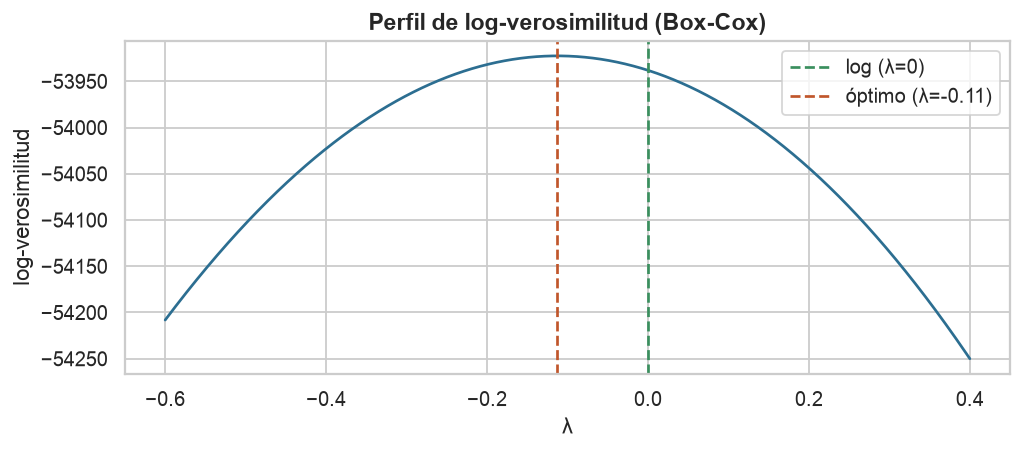

In [38]:
from scipy.stats import boxcox, boxcox_llf, chi2
precio = pd.to_numeric(df["eda_precio_usd"], errors="coerce").dropna().values
_, lam = boxcox(precio)
ls = np.linspace(-0.6, 0.4, 4001); llf = np.array([boxcox_llf(l, precio) for l in ls])
ic = ls[llf >= llf.max() - chi2.ppf(0.95, 1) / 2]
d_log = llf.max() - boxcox_llf(0, precio)
print(f"λ (MLE) = {lam:.3f}   ·   IC 95% = [{ic.min():.3f}, {ic.max():.3f}]   ·   ¿incluye 0? {ic.min() <= 0 <= ic.max()}")
print(f"log-verosimilitud: óptimo = {llf.max():,.0f}  vs.  log (λ=0) = {boxcox_llf(0, precio):,.0f}   (Δ = {d_log:.1f})")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ls, llf, color=PAL)
ax.axvline(0, color=ACCENT, ls="--", lw=1.5, label="log (λ=0)")
ax.axvline(lam, color=PAL2, ls="--", lw=1.5, label=f"óptimo (λ={lam:.2f})")
ax.set(title="Perfil de log-verosimilitud (Box-Cox)", xlabel="λ", ylabel="log-verosimilitud"); ax.legend(); plt.show()

**Decisión.** El óptimo es $\lambda\approx-0{,}11$ y su IC 95% no incluye 0, así que en sentido
estricto Box-Cox no confirma el log: con ~4.800 observaciones el test detecta hasta un desvío trivial.
Pero la mejora de ajuste sobre el log es marginal ($\Delta$ verosimilitud $\approx15{,}6$) y ese
$\lambda$ óptimo no tiene interpretación. Por eso se adopta el **logaritmo** ($\lambda=0$): se redondea
a un $\lambda$ interpretable cercano al óptimo (Box & Cox, 1964; Montgomery et al., 2012), da
coeficientes en % y elasticidades, hace tratable el *retransformation bias* (Duan, 1983) y es la forma
**semi-log** convencional en hedónicos (Malpezzi, 2003). No es el óptimo estadístico estricto, pero sí
la elección correcta, con una pérdida de ajuste insignificante.

## 1. Especificación y estimación

El objeto evaluado en validación cruzada es el **pipeline completo** (preprocesamiento + OLS): las
categóricas se imputan e *one-hotean*, las numéricas se imputan (mediana) y escalan, y todo se ajusta
**solo con el train** de cada fold. Se estima el mismo esquema para los cuatro escenarios sobre **las
mismas particiones**, condición necesaria para comparar de forma pareada (protocolo §4).

In [39]:
CAT = {"eda_antiguedad_estado","eda_disposicion","eda_orientacion","eda_tipo_operacion","barrio_oficial_geo"}
BIN = set(feat_cols) | {"fe_tiene_cochera","fe_expensas_informadas"}

def preprocesador(cols):
    cat = [c for c in cols if c in CAT]
    binz = [c for c in cols if c in BIN]
    num = [c for c in cols if c not in cat and c not in binz]
    return ColumnTransformer([
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                          ("o", OneHotEncoder(handle_unknown="ignore", min_frequency=10))]), cat),
        ("bin", "passthrough", binz),
        ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
    ], remainder="drop")

def cv_eval(cols):
    gkf = GroupKFold(n_splits=5); oof = np.full(len(y), np.nan); filas = []
    for tr, te in gkf.split(df, y, groups):
        pipe = Pipeline([("p", preprocesador(cols)), ("m", LinearRegression())]).fit(df.iloc[tr][cols], y[tr])
        p = pipe.predict(df.iloc[te][cols]); oof[te] = p
        yt, ytu, ypu = y[te], np.expm1(y[te]), np.expm1(p)
        filas.append(dict(rmse_usd=np.sqrt(mean_squared_error(ytu, ypu)), mae_usd=mean_absolute_error(ytu, ypu),
                          mape=np.mean(np.abs((ytu-ypu)/ytu))*100, r2_log=r2_score(yt, p)))
    return pd.DataFrame(filas), oof

res, oofs = {}, {}
for k, cols in escenarios.items():
    res[k], oofs[k] = cv_eval(cols)
print("Estimados los 4 escenarios sobre las mismas particiones (5-fold group-aware).")

Estimados los 4 escenarios sobre las mismas particiones (5-fold group-aware).


## 2. Valor incremental de la información (S1→S4) — RQ2

Cada escenario **suma** su bloque de información al anterior. Comparar su desempeño fuera de muestra
mide cuánto aporta cada grupo de variables.

,features,RMSE_USD,MAE_USD,MAPE_%,R2_log,R2_sd
S1,19.0,86121.0,35557.0,23.7,0.820,0.011
S2,22.0,73285.0,32363.0,21.3,0.847,0.006
S3,26.0,72649.0,32102.0,21.2,0.849,0.008
S4,45.0,64571.0,30265.0,19.8,0.866,0.005


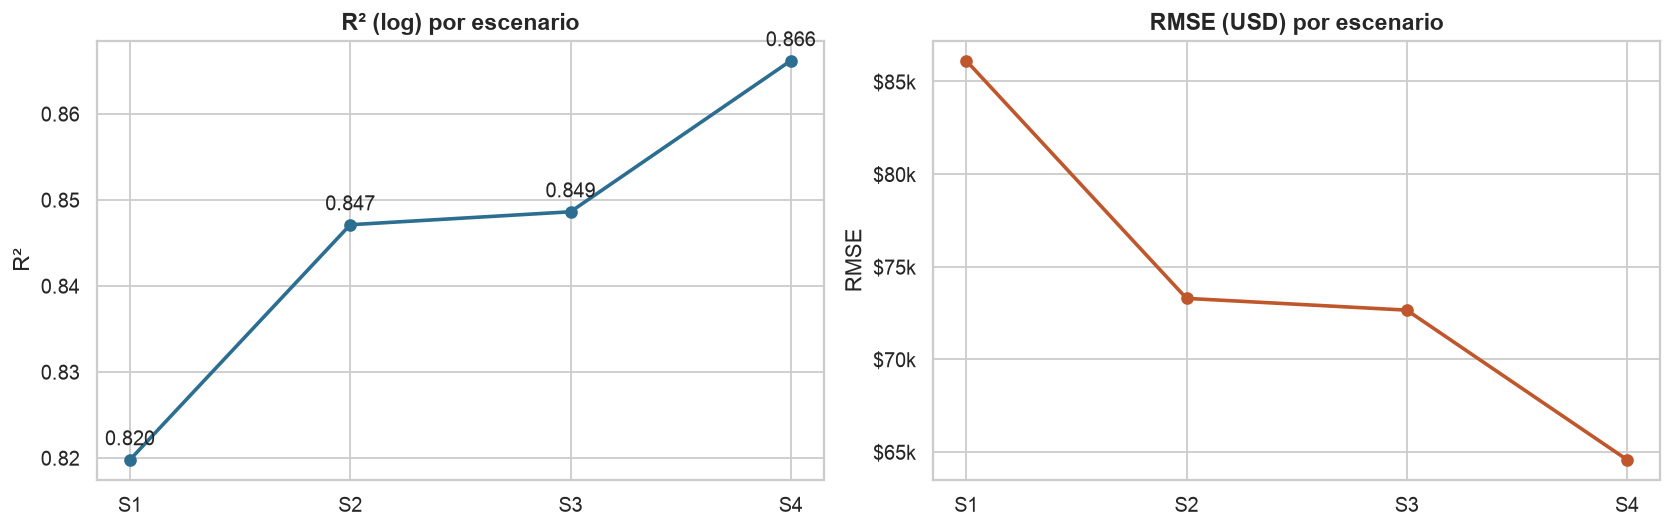

In [40]:
tabla = pd.DataFrame({k: {"features": len(escenarios[k]),
                           "RMSE_USD": res[k].rmse_usd.mean(), "MAE_USD": res[k].mae_usd.mean(),
                           "MAPE_%": res[k].mape.mean(), "R2_log": res[k].r2_log.mean(),
                           "R2_sd": res[k].r2_log.std()} for k in res}).T
display(tabla.round({"features":0,"RMSE_USD":0,"MAE_USD":0,"MAPE_%":1,"R2_log":3,"R2_sd":3}))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].plot(tabla.index, tabla["R2_log"], "o-", color=PAL, lw=2)
for i, v in enumerate(tabla["R2_log"]): axs[0].annotate(f"{v:.3f}", (i, v), textcoords="offset points", xytext=(0,8), ha="center")
axs[0].set(title="R² (log) por escenario", ylabel="R²", xlabel="")
axs[1].plot(tabla.index, tabla["RMSE_USD"], "o-", color=PAL2, lw=2)
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f"${x/1e3:.0f}k"))
axs[1].set(title="RMSE (USD) por escenario", ylabel="RMSE", xlabel="")
plt.show()

**Interpretación.** El salto mayor está en **S1→S2 (localización)**: incorporar barrio y
coordenadas mejora sustancialmente el ajuste, consistente con el peso de la ubicación en la teoría
hedónica y con la heterogeneidad territorial que vimos en el EDA. **S2→S3 (microlocalización)** aporta
**poco al baseline lineal**: en un distrito compacto, el barrio ya absorbe casi toda la señal de
localización, y las distancias agregan un margen menor —un hallazgo honesto, que además anticipa que
un modelo **no lineal** (RF/LightGBM) podría explotar mejor esas variables—. **S3→S4 (texto)** vuelve
a aportar señal: las amenities y atributos derivados de la descripción mejoran la predicción. El
patrón —localización y texto como los bloques más informativos— es coherente con los antecedentes de
AVM (Gutiérrez et al., 2026; Tapia et al., 2025).

### Diagnóstico de sobreajuste: entrenamiento vs. test (S1→S4)

Hasta acá reportamos **test** (fuera de fold). Para ver si el modelo **sobreajusta**, comparamos su
desempeño en **entrenamiento** y en **test** por escenario, con la **brecha** entre ambos. Si train ≈
test, el modelo no memoriza; si train ≫ test, sí. Este diagnóstico es central para la explicabilidad y
para contrastar el hedónico con los modelos flexibles.

,features,R2_train,R2_test,brecha_R2,RMSE_train,RMSE_test
escenario,,,,,,
S1,19,0.827,0.820,0.007,73430.0,86121.0
S2,22,0.854,0.847,0.007,64391.0,73285.0
S3,26,0.857,0.849,0.009,63687.0,72649.0
S4,45,0.875,0.866,0.009,57507.0,64571.0


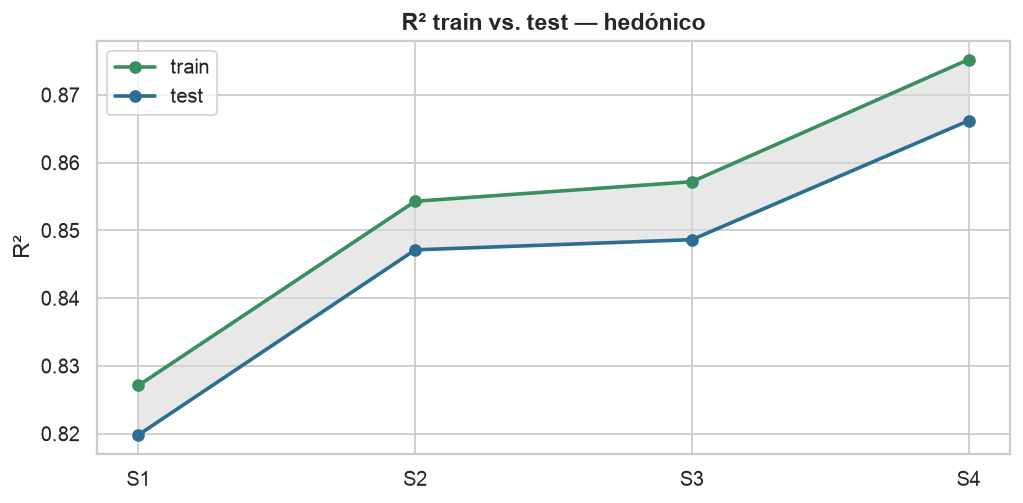

In [41]:
def train_test(cols):
    gkf = GroupKFold(5); r2tr=[]; r2te=[]; rmtr=[]; rmte=[]
    for a, b in gkf.split(df, y, groups):
        pipe = Pipeline([("p", preprocesador(cols)), ("m", LinearRegression())]).fit(df.iloc[a][cols], y[a])
        pa, pb = pipe.predict(df.iloc[a][cols]), pipe.predict(df.iloc[b][cols])
        r2tr.append(r2_score(y[a], pa)); r2te.append(r2_score(y[b], pb))
        rmtr.append(np.sqrt(mean_squared_error(np.expm1(y[a]), np.expm1(pa))))
        rmte.append(np.sqrt(mean_squared_error(np.expm1(y[b]), np.expm1(pb))))
    return np.mean(r2tr), np.mean(r2te), np.mean(rmtr), np.mean(rmte)

filas = []
for k, cols in escenarios.items():
    a, b, c, d = train_test(cols)
    filas.append({"escenario": k, "features": len(cols), "R2_train": a, "R2_test": b,
                  "brecha_R2": a - b, "RMSE_train": c, "RMSE_test": d})
ttab = pd.DataFrame(filas).set_index("escenario")
display(ttab.round({"features":0,"R2_train":3,"R2_test":3,"brecha_R2":3,"RMSE_train":0,"RMSE_test":0}))

fig, ax = plt.subplots(figsize=(8, 4)); x = np.arange(len(ttab))
ax.plot(x, ttab["R2_train"], "o-", color=ACCENT, lw=2, label="train")
ax.plot(x, ttab["R2_test"], "o-", color=PAL, lw=2, label="test")
ax.fill_between(x, ttab["R2_test"], ttab["R2_train"], color="0.85", alpha=.6)
ax.set(title="R² train vs. test — hedónico", ylabel="R²", xticks=x); ax.set_xticklabels(list(ttab.index)); ax.legend()
plt.show()

**Interpretación.** La **brecha train–test es muy pequeña** en todos los escenarios (~0,01 de R²):
el hedónico rinde de forma similar en datos vistos y no vistos, lo que sería **compatible con la ausencia
de sobreajuste apreciable**. Con ~60 columnas sobre ~3.800 avisos de entrenamiento por fold, la relación
observaciones/parámetros es holgada, condición asociada a baja varianza del estimador. Su limitación
tendería a ubicarse entonces del lado del **sesgo** más que de la varianza: el techo de R² (~0,86) se
alcanza tanto en train como en test, lo que sería consistente con que la **forma lineal** no llega a
capturar la estructura de la relación. Esto ofrecería una explicación de por qué la regularización
(notebook 02) no mejoró el ajuste —no habría sobreajuste que corregir— y de por qué un modelo flexible sí
podría hacerlo. Como referencia, el Random Forest sobre estos mismos datos presenta una brecha mayor
(~0,10), compatible con un ajuste más estrecho del entrenamiento, y aun así mejor desempeño en test.
Ambos comportamientos ilustrarían las dos caras del compromiso sesgo–varianza.

## 3. Diagnósticos del modelo (Montgomery, Peck & Vining)

Evaluamos los supuestos de la regresión sobre las **predicciones fuera de muestra (OOF)** del
escenario completo (S4), no in-sample: predicho vs. observado, residuos vs. predicho
(heterocedasticidad), Q-Q de residuos (normalidad) y su distribución.

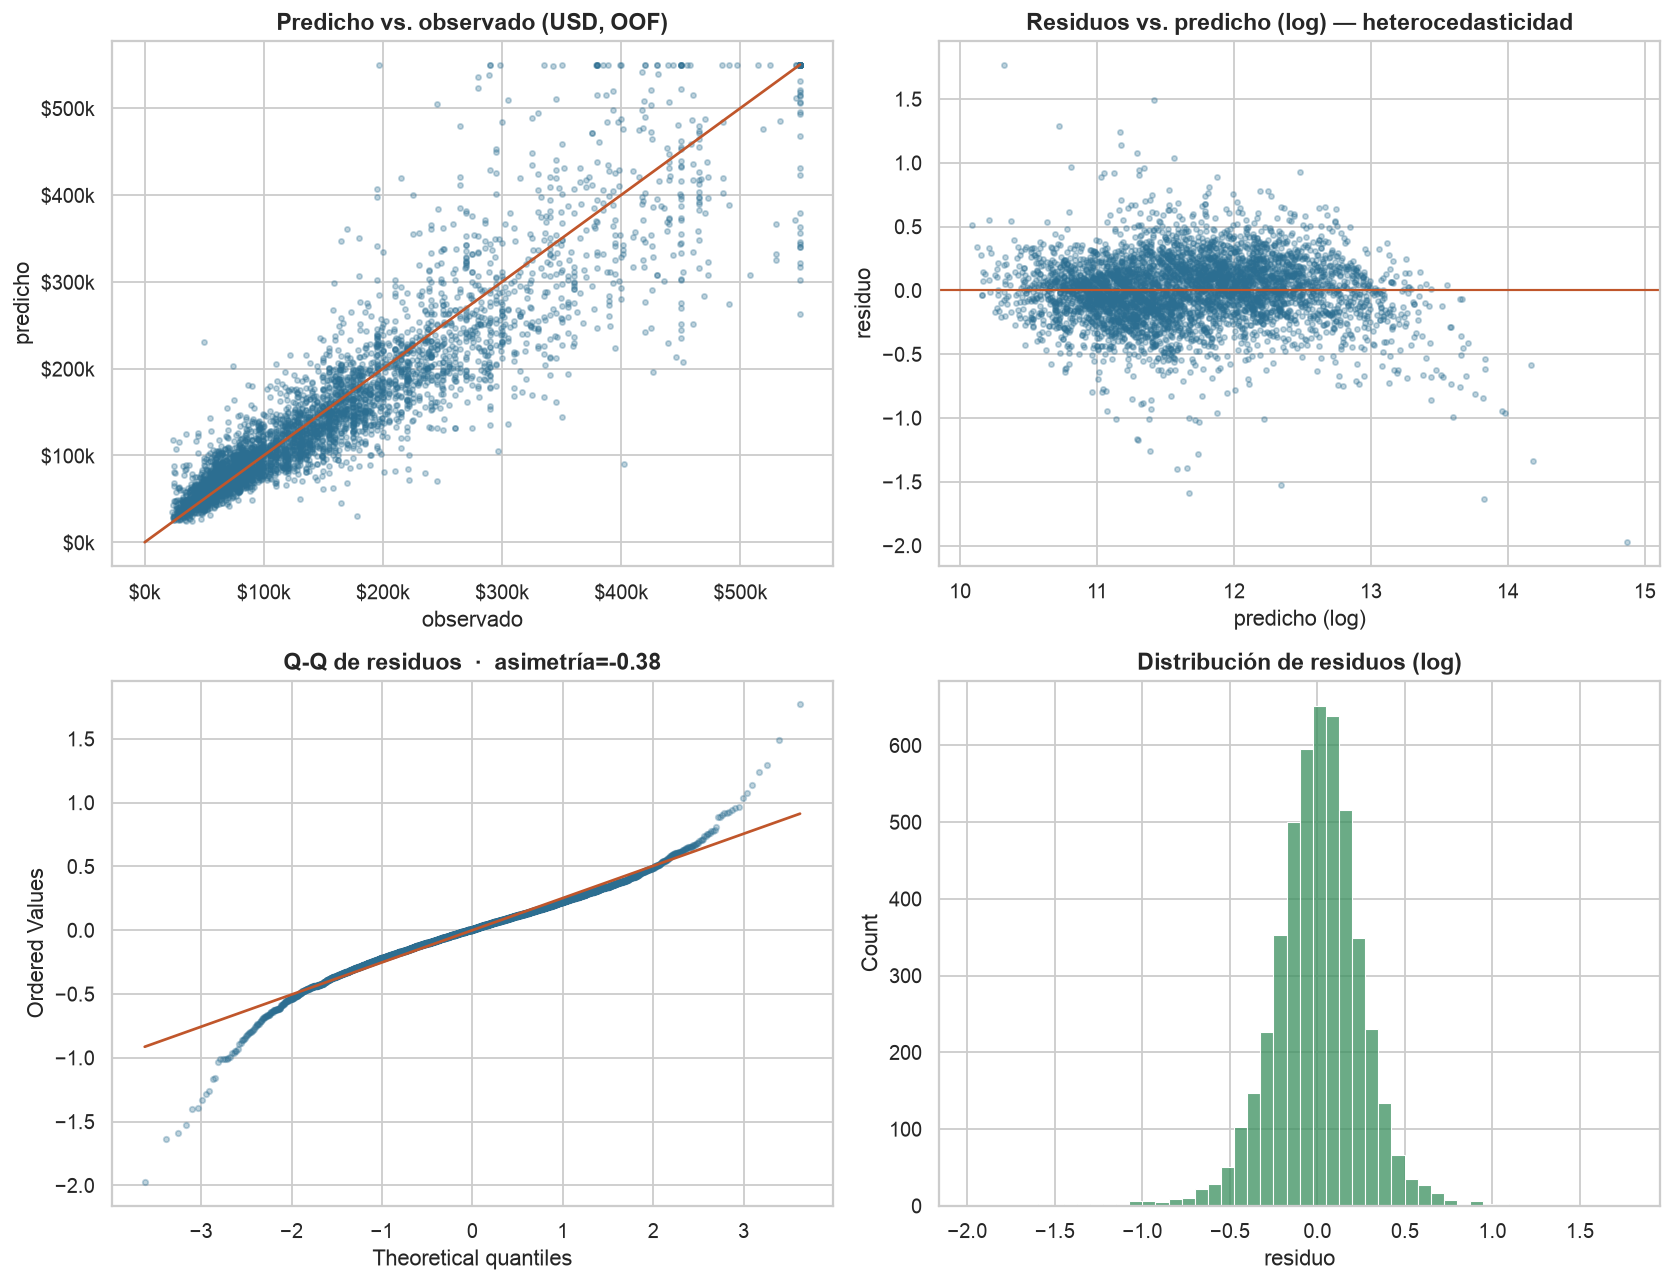

R²(log) OOF S4: 0.867  ·  residuo: media 0.000, sd 0.257


In [42]:
oof = oofs["S4"]; resid = y - oof
ytu, ypu = np.expm1(y), np.expm1(oof)
fig, axs = plt.subplots(2, 2, figsize=(13, 10))

lim = np.percentile(ytu, 99)
axs[0,0].scatter(ytu.clip(0,lim), ypu.clip(0,lim), s=8, alpha=.3, color=PAL)
axs[0,0].plot([0,lim],[0,lim], color=PAL2, lw=1.5)
for ax in [axs[0,0]]:
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f"${x/1e3:.0f}k"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f"${x/1e3:.0f}k"))
axs[0,0].set(title="Predicho vs. observado (USD, OOF)", xlabel="observado", ylabel="predicho")

axs[0,1].scatter(oof, resid, s=8, alpha=.3, color=PAL)
axs[0,1].axhline(0, color=PAL2, lw=1.2)
axs[0,1].set(title="Residuos vs. predicho (log) — heterocedasticidad", xlabel="predicho (log)", ylabel="residuo")

stats.probplot(resid, dist="norm", plot=axs[1,0])
axs[1,0].get_lines()[0].set(marker="o", markersize=3, alpha=.3, color=PAL); axs[1,0].get_lines()[1].set(color=PAL2)
axs[1,0].set_title(f"Q-Q de residuos  ·  asimetría={stats.skew(resid):.2f}")

sns.histplot(resid, bins=50, color=ACCENT, ax=axs[1,1]); axs[1,1].set(title="Distribución de residuos (log)", xlabel="residuo")
plt.show()
print(f"R²(log) OOF S4: {r2_score(y, oof):.3f}  ·  residuo: media {resid.mean():.3f}, sd {resid.std():.3f}")

**Interpretación.** Los cuatro paneles chequean los supuestos sobre las predicciones fuera de fold
—el error honesto, no el de "corregir con las respuestas a la vista"—. En **predicho vs. observado** la
nube sigue la diagonal (el modelo acierta la tendencia) pero **se abre en los precios altos**, donde
erra más en dólares. En **residuos vs. predicho** la banda debería ser pareja; se **ensancha un poco**
en un extremo, patrón compatible con **heterocedasticidad leve** (varianza no constante), algo habitual en
precios de vivienda aun en log: no invalidaría el modelo, pero respaldaría el uso de **errores estándar
robustos** para la inferencia de coeficientes (lo hacemos en la sección 5). El **Q-Q** cae sobre la recta
en el centro y se despega en las puntas → **colas algo pesadas**, es decir, unos pocos avisos con errores
grandes, comportamiento frecuente en mercados con casos atípicos. El **histograma** describe una campana
**centrada en cero** (media −0,001; desvío 0,258, un error típico del orden del 26% en escala log),
compatible con la **ausencia de sesgo sistemático** hacia arriba o hacia abajo. En conjunto, el baseline
luciría **razonablemente especificado**, con las limitaciones esperables de una forma lineal
—heterocedasticidad leve y colas—, más marcadas en los extremos de precio.

## 4. Análisis de errores por segmento

El error medio esconde heterogeneidad. Miramos el **error porcentual absoluto (APE)** fuera de muestra
por barrio y por rango de precio (protocolo §10: no interpretar solo la media).

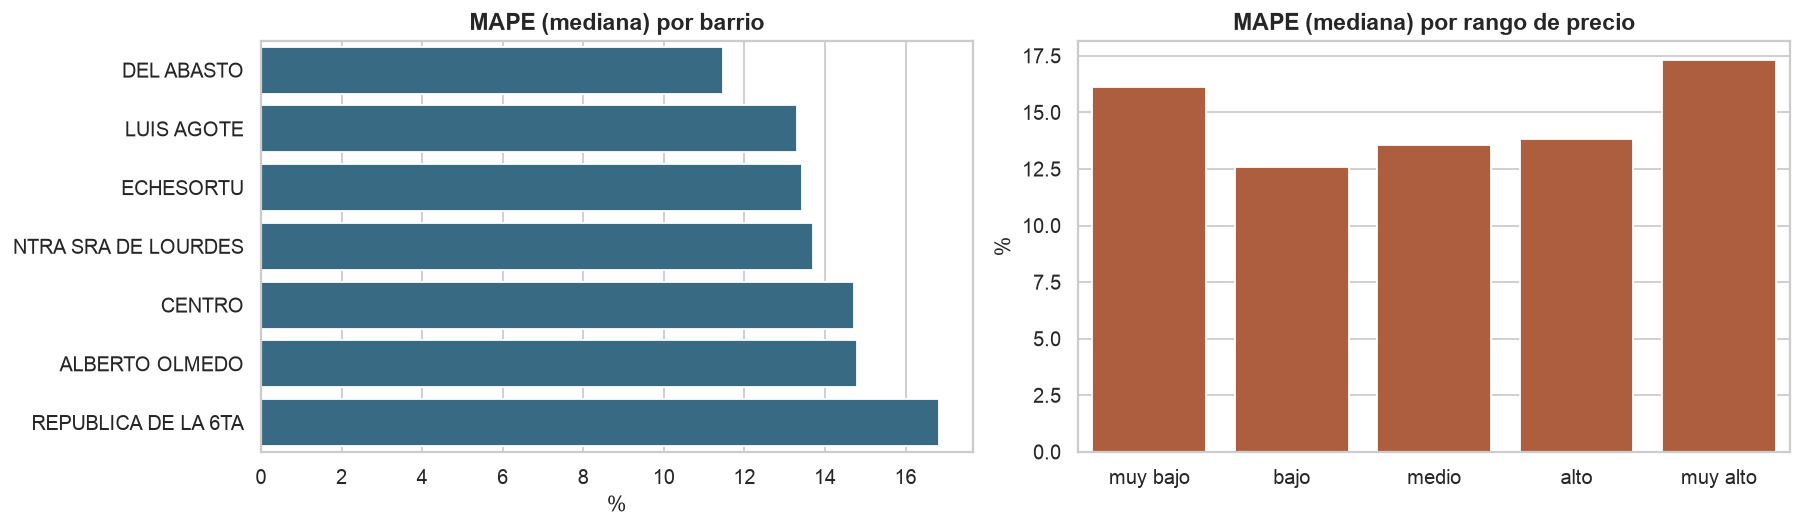

In [43]:
ape = np.abs((ytu - ypu) / ytu) * 100
d = pd.DataFrame({"ape": ape, "barrio": df["barrio_oficial_geo"], "precio": ytu})
top = d["barrio"].value_counts().head(7).index
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
b = d[d["barrio"].isin(top)].groupby("barrio")["ape"].median().sort_values()
sns.barplot(x=b.values, y=b.index, color=PAL, ax=axs[0]); axs[0].set(title="MAPE (mediana) por barrio", xlabel="%", ylabel="")
d["q"] = pd.qcut(d["precio"], 5, labels=["muy bajo","bajo","medio","alto","muy alto"])
q = d.groupby("q")["ape"].median()
sns.barplot(x=q.index, y=q.values, color=PAL2, ax=axs[1]); axs[1].set(title="MAPE (mediana) por rango de precio", xlabel="", ylabel="%")
plt.show()

**Interpretación.** El error medio esconde bastante. **Por barrio**, el modelo no rinde igual en
todos: anda mejor en Del Abasto (~12% de error típico) y peor en República de la 6ta (~17%), una brecha
de unos 5 puntos que sugeriría **heterogeneidad territorial** no del todo capturada por la forma lineal.
**Por rango de precio**, el error dibuja una **U**: más alto en los extremos —propiedades muy baratas
(~16%) y sobre todo muy caras (~18%)— y más bajo en el centro del mercado (~12–14%). Tiene sentido: las
unidades del medio son las más "estándar" y abundantes, así que el modelo las aprende bien, mientras que
las muy baratas suelen ser casos atípicos y las muy caras son pocas, únicas y difíciles de tasar
linealmente. Reportar solo el promedio (~20% de MAPE) sería engañoso; y estos segmentos difíciles son
justamente donde se espera que un modelo flexible aporte (Gyger et al., 2026), lo que orienta la
comparación de la etapa siguiente.

## 5. Interpretación de coeficientes (regresión hedónica)

Estimamos una especificación hedónica **interpretable** con OLS (statsmodels) sobre una selección de
atributos, en forma semi-log. Los coeficientes se leen como **efecto porcentual sobre el precio**
($100\,(e^{\beta}-1)$); el de $\log(\text{superficie})$ es una **elasticidad** (Caffo, 2015;
Montgomery et al., 2012). Esta estimación es para **interpretación** (asociaciones en la muestra), no
para medir performance —eso lo dan las métricas OOF de arriba—.

In [44]:
d = df.copy()
d["eda_cocheras"] = pd.to_numeric(d["eda_cocheras"], errors="coerce").fillna(0)
mv = ["eda_precio_usd","eda_superficie_total_m2","eda_ambientes","eda_banos","eda_cocheras",
      "eda_antiguedad_anos","eda_disposicion","eda_orientacion","fe_dist_centro_km",
      "fe_dist_espacio_verde_km","feat_a_estrenar","feat_cochera","feat_amenities","feat_vista_rio"]
mv = [c for c in mv if c in d.columns]
d = d.dropna(subset=mv); d = d[d["eda_superficie_total_m2"] > 0]
formula = ("np.log1p(eda_precio_usd) ~ np.log(eda_superficie_total_m2) + eda_ambientes + eda_banos "
           "+ eda_cocheras + eda_antiguedad_anos + C(eda_disposicion) + C(eda_orientacion) "
           "+ fe_dist_centro_km + fe_dist_espacio_verde_km + feat_a_estrenar + feat_cochera "
           "+ feat_amenities + feat_vista_rio")
mod = smf.ols(formula, data=d).fit(cov_type="HC1")   # errores robustos (heterocedasticidad)
coef = pd.DataFrame({"beta": mod.params, "efecto_%": (np.exp(mod.params)-1)*100,
                     "p_valor": mod.pvalues})
# el %efecto (100·(e^β−1)) solo aplica a regresores en nivel; en el intercepto y en log(superficie)
# β se lee distinto (β de log = elasticidad), así que ahí no se reporta %efecto
_m = coef.index.str.contains("Intercept") | coef.index.str.contains(r"np\.log")
coef.loc[_m, "efecto_%"] = np.nan
display(coef.round(3))
print("Nota: en np.log(superficie), β = elasticidad (%Δprecio por %Δsuperficie).")
print(f"N = {int(mod.nobs):,}  ·  R² = {mod.rsquared:.3f}  ·  R² ajustado = {mod.rsquared_adj:.3f}")

,beta,efecto_%,p_valor
Intercept,7.934,NaN,0.000
C(eda_disposicion)[T.Frente],0.065,6.765,0.000
C(eda_disposicion)[T.Interno],-0.045,-4.415,0.029
C(eda_disposicion)[T.Lateral],0.031,3.107,0.389
C(eda_orientacion)[T.N],0.018,1.821,0.145
C(eda_orientacion)[T.NE],0.001,0.138,0.962
C(eda_orientacion)[T.NO],0.024,2.462,0.407
C(eda_orientacion)[T.O],-0.014,-1.433,0.256
C(eda_orientacion)[T.S],-0.013,-1.276,0.318
C(eda_orientacion)[T.SE],-0.016,-1.561,0.637


Nota: en np.log(superficie), β = elasticidad (%Δprecio por %Δsuperficie).
N = 3,124  ·  R² = 0.881  ·  R² ajustado = 0.880


**Interpretación.** En la forma semi-log cada coeficiente se lee como **efecto porcentual** sobre
el precio (columna `efecto_%`), y el p-valor dice si es significativo. La **superficie** entra en log,
así que su coeficiente es una **elasticidad**: +1% de superficie ≈ **+0,82%** de precio —el efecto más
fuerte y, como espera la teoría, muy significativo—. Entre los atributos en nivel, un **baño** adicional
se asocia a ~**+11,6%**, una **cochera** a ~**+7,3%**, un **ambiente** a ~+4,2%, y cada **año** de
antigüedad resta ~0,8%. Las **amenities** del texto son primas de calidad nítidas: **vista al río
~+19%**, amenities ~+16%. La **disposición** ordena frente (**+6,8%**) por encima de interno (−4,4%).
Vale la pena mirar también lo que **no** es significativo: la **orientación** (todos los p-valores
altos), *a estrenar* y la distancia a espacios verdes no mueven el precio de forma detectable una vez
controlado el resto —en su mayoría, las mismas variables que el Lasso descartó en el notebook 02, una
coincidencia que aportaría respaldo a la lectura—. Usamos **errores estándar robustos (HC1)** por la
heterocedasticidad, y los coeficientes se leen como **asociaciones condicionales**, no como efectos
causales aislados; por eso a continuación chequeamos la colinealidad con el VIF.

In [45]:
num = [c for c in ["eda_superficie_total_m2","eda_ambientes","eda_banos","eda_cocheras",
                        "eda_antiguedad_anos","fe_dist_centro_km","fe_dist_espacio_verde_km"] if c in d.columns]
X = d[num].assign(_const=1.0)
vif = pd.DataFrame({"VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]},
                   index=X.columns).drop("_const").sort_values("VIF", ascending=False)
display(vif.round(2))

,VIF
eda_superficie_total_m2,2.99
eda_ambientes,2.71
eda_banos,2.25
eda_antiguedad_anos,1.36
eda_cocheras,1.22
fe_dist_centro_km,1.10
fe_dist_espacio_verde_km,1.03


**Multicolinealidad (VIF).** Valores por encima de ~5–10 (Montgomery et al., 2012) señalan
colinealidad relevante. En esta especificación **todos los VIF son bajos (< 3)**: no hay
multicolinealidad problemática, y los coeficientes podrían interpretarse con razonable confianza. Conviene volver
a chequearlo si se incorporan los **ratios** (superficie/ambiente, etc.), que por construcción inflan
el VIF; para la **predicción**, en cambio, la colinealidad no invalida el modelo. La vía principiada
para manejar colinealidad y selección de variables es la **regularización** (ridge / LASSO; ISL cap. 6;
ESL cap. 3), que se aplicará **por fold** en la etapa de modelado.

### Observaciones influyentes (distancia de Cook)

La **distancia de Cook** (Montgomery, Peck & Vining, 2012, cap. 6) mide cuánto cambia el ajuste al
excluir cada observación: identifica los avisos que **traccionan desproporcionadamente** los
coeficientes. Regla práctica: se consideran influyentes los puntos con $D_i > 4/n$.

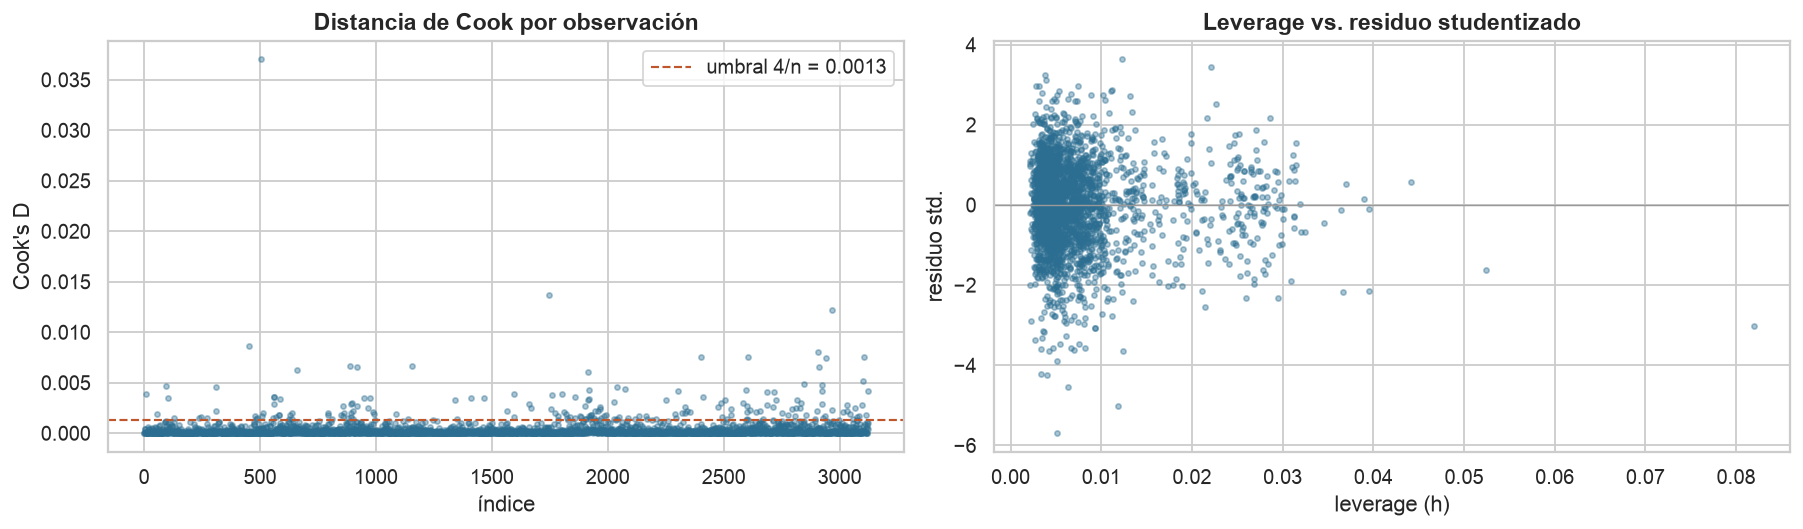

Observaciones influyentes (Cook > 4/n): 188 de 3,124 (6.0%)


In [46]:
from statsmodels.stats.outliers_influence import OLSInfluence
infl = OLSInfluence(mod)
cook = infl.cooks_distance[0]; lev = infl.hat_matrix_diag; rstd = infl.resid_studentized_internal
n = len(cook); umbral = 4 / n
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
axs[0].scatter(range(n), cook, s=8, alpha=.4, color=PAL)
axs[0].axhline(umbral, color=PAL2, ls="--", lw=1.2, label=f"umbral 4/n = {umbral:.4f}")
axs[0].set(title="Distancia de Cook por observación", xlabel="índice", ylabel="Cook's D"); axs[0].legend()
axs[1].scatter(lev, rstd, s=8, alpha=.4, color=PAL); axs[1].axhline(0, color="#999", lw=.8)
axs[1].set(title="Leverage vs. residuo studentizado", xlabel="leverage (h)", ylabel="residuo std.")
plt.show()
print(f"Observaciones influyentes (Cook > 4/n): {int((cook>umbral).sum())} de {n:,} "
      f"({(cook>umbral).mean()*100:.1f}%)")

**Interpretación.** Un conjunto acotado de observaciones supera el umbral de Cook: son avisos con
combinaciones atípicas de atributos y precio (en su mayoría, propiedades premium legítimas, no
errores). No se eliminan —coherente con la política de outliers definida en el preprocesamiento—, pero
quedan **identificados** como chequeo de robustez del baseline: su exclusión sensibilizaría los
coeficientes, algo a reportar si se hace inferencia fina.

## 6. Conclusiones

**Qué logra el baseline.** El modelo hedónico alcanza un **R²(log) de ~0,82–0,86** fuera de muestra
según el escenario, con la **localización (S2)** y el **texto (S4)** como los bloques más informativos y
la **microlocalización (S3)** aportando poco al ajuste lineal. Los diagnósticos lo muestran
**razonablemente especificado** —residuos centrados en cero, con heterocedasticidad leve y colas algo
pesadas—, y el análisis por segmento revela que el error se concentra en los **extremos de precio** y
varía entre barrios. Los coeficientes, leídos como efectos porcentuales, son **coherentes con la teoría
hedónica**: la superficie manda (elasticidad ~0,82), y baños, cocheras, amenities y vista al río suman
primas positivas y significativas.

**Qué agrega la comparación con la regularización (notebook 02).** Poner el hedónico al lado de
Ridge/Lasso/ElasticNet deja tres lecturas que se refuerzan entre sí:

- **No se observa sobreajuste apreciable en el baseline.** Los modelos penalizados alcanzan un R² y un
  RMSE muy similares a los del OLS: con ~4.800 avisos y ~60 columnas, no habría sobreajuste que corregir.
  El aporte de la regularización sería sobre todo de **estabilidad** (menor varianza del error entre
  folds), con **ElasticNet** como el más parejo.
- **La interpretación luce robusta.** Las variables que aquí resultan **no significativas** (orientación,
  *a estrenar*, distancia a espacios verdes) coinciden, en gran medida, con **las que el Lasso descarta**;
  y la jerarquía de efectos es similar a la de los coeficientes penalizados. Que dos abordajes distintos
  —p-valores del OLS y encogimiento del Lasso— señalen a los mismos predictores constituiría **evidencia
  convergente**.
- **Cautela con la colinealidad en la especificación completa.** En este notebook la especificación
  interpretable presenta VIF bajos, pero en el escenario S4 completo la colinealidad se hace visible: el
  notebook 02 mostró que el coeficiente de la **latitud cambia de signo** en OLS, en presencia de la
  longitud, y se estabiliza al regularizar. Esto sugeriría leer los coeficientes como **asociaciones
  condicionales** y, para selección/estabilidad, apoyarse en la regularización dentro del pipeline.

**Límites y próximo paso.** Los límites son los de una forma lineal: no capta interacciones ni no
linealidades por sí sola (ISL cap. 3; Montgomery et al. cap. 8), y la heterogeneidad del error por
segmento —junto con la fragilidad de la microlocalización en el modelo lineal— sugiere margen para
modelos flexibles. Eso motiva la etapa siguiente: **Random Forest y LightGBM sobre las mismas
particiones**, la comparación pareada hedónico vs. ML (RQ1), el diagnóstico espacial de residuos
(Moran's I) y el *spatial lag* por fold (RQ3–RQ4), y la interpretabilidad por SHAP (RQ5) —donde veremos
si los árboles rescatan la señal de microlocalización que el lineal deja pasar—.

## Referencias

**Libros (fundamento metodológico)**

- Montgomery, D. C., Peck, E. A., & Vining, G. G. (2012). *Introduction to Linear Regression Analysis* (5ª ed.). Wiley. — estimación, diagnóstico de residuos, multicolinealidad (VIF), variables indicadoras, especificación.
- Caffo, B. (2015). *Regression Models for Data Science in R*. Leanpub (Johns Hopkins). — regresión lineal, interpretación de coeficientes y modelos log-lineales.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2ª ed.), §7.10.2. Springer. — validación cruzada sin fuga.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning*. Springer. — regresión, resampling.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer. — preprocesamiento dentro del fold.

**Artículos y antecedentes**

- Rosen, S. (1974). Hedonic prices and implicit markets. *Journal of Political Economy, 82*(1), 34–55.
- Malpezzi, S. (2003). Hedonic pricing models: a selective and applied review. En *Housing Economics and Public Policy*. Blackwell.
- Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B, 26*(2), 211–252.
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *JASA, 78*(383), 605–610.
- Zaki et al. (2022); Yazdani (2021) — hedónico vs. ML en precios inmobiliarios.
- Gutiérrez et al. (2026); Tapia et al. (2025); Gyger et al. (2026) — antecedentes AVM.